In [2]:
%load_ext autoreload
%autoreload 2
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
plt.rcParams['figure.figsize'] = (12, 5)
plt.rcParams.update({'errorbar.capsize': 3})
plt.rcParams['xtick.labelsize']= 13
plt.rcParams['ytick.labelsize']= 13
plt.rcParams.update({'axes.labelsize': 16})

In [3]:
from astropy import constants, units

c_kms=constants.c.value/10**3

In [4]:
import h5py
from astropy.io import ascii

In [5]:
from lmfit import Model

In [6]:

def gaussian_w_slope(x, amp, cen, wid, bas,slope=0):
    "1-d gaussian: gaussian(x, amp, cen, wid,bas,slope)"
    return (amp/(np.sqrt(2*np.pi)*wid)) * np.exp(-(x-cen)**2 /(2*wid**2)) + bas+x*slope

In [7]:
def wl2vel(wl_arr,central_wl=None):
    '''returns vel in km/s
    
        inputs are wl_arr and central_wl'''
    if central_wl==None:
        central_wl=np.average(wl_arr)

    #print(c_kms)
    vel_arr=(wl_arr-central_wl)*c_kms/central_wl
    return vel_arr

In [8]:
#read coadds from coadds_outputs.h5 

data=h5py.File('coadds_outputs.h5','r')

In [9]:
data

<HDF5 file "coadds_outputs.h5" (mode r)>

In [10]:
data.keys()

<KeysViewHDF5 ['EXPRES', 'NEID', 'overlaps']>

In [11]:
data['NEID']

<HDF5 group "/NEID" (4 members)>

In [12]:
data['NEID'].keys()

<KeysViewHDF5 ['coadds', 'date_sets', 'uncs', 'wls']>

In [13]:
for key in data['NEID']['coadds'].keys():
    #if the shape is greater than 1, print the key and shape
    if data['NEID']['coadds'][key].shape[0]>1:
        print(key, data['NEID']['coadds'][key].shape)

0076 (122, 9216)
0077 (122, 9216)


In [14]:
list(data['NEID']['coadds']['0076'])

[array([nan, nan, nan, ..., nan, nan, nan]),
 array([nan, nan, nan, ..., nan, nan, nan]),
 array([nan, nan, nan, ..., nan, nan, nan]),
 array([-0.22002384, -0.01702587, -0.67824998, ...,         nan,
                nan,         nan]),
 array([        nan,         nan,         nan, ...,  0.04735026,
        -0.34480251, -0.07986586]),
 array([nan, nan, nan, ..., nan, nan, nan]),
 array([nan, nan, nan, ..., nan, nan, nan]),
 array([-0.02807862, -0.04519363,  0.06150554, ...,  0.07337228,
         0.03466466,  0.11789356]),
 array([-0.20199335, -0.11950383,  0.10707737, ...,  0.00486623,
         0.0706157 , -0.01625383]),
 array([-0.06784296,  0.18237221, -0.08384316, ...,  0.24565475,
         0.21340046,  0.28661537]),
 array([ 0.10441107,  0.05873122, -0.17328136, ...,  0.22818156,
         0.21236393,  0.24535006]),
 array([-0.17816693, -0.09170771, -0.21126226, ...,  0.35397795,
         0.34404272,  0.36887211]),
 array([-0.15908801, -0.03416314,  0.00894035, ...,  0.53096042,
   

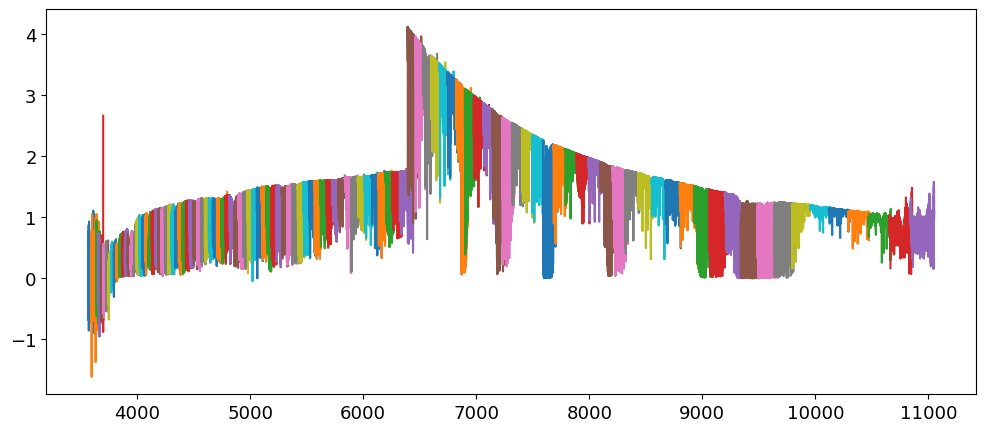

In [15]:
for o in range(data['NEID']['coadds']['0076'].shape[0]):
    #if the mean wavelength is greater than 1000, plot the coadd
    if np.mean(data['NEID']['wls']['0076'][o])>1000:
        plt.plot(data['NEID']['wls']['0076'][o],data['NEID']['coadds']['0076'][o])

In [16]:
np.array(data['NEID']['coadds']['0076'])

array([[       nan,        nan,        nan, ...,        nan,        nan,
               nan],
       [       nan,        nan,        nan, ...,        nan,        nan,
               nan],
       [       nan,        nan,        nan, ...,        nan,        nan,
               nan],
       ...,
       [1.19532835, 1.69411545, 1.439161  , ..., 0.39184272, 0.20450764,
        0.5833682 ],
       [       nan,        nan,        nan, ...,        nan,        nan,
               nan],
       [       nan,        nan,        nan, ...,        nan,        nan,
               nan]])

In [17]:
np.array(data['NEID']['coadds'])

array(['0000', '0001', '0002', '0003', '0004', '0005', '0006', '0007',
       '0008', '0009', '0010', '0011', '0012', '0013', '0014', '0015',
       '0016', '0017', '0018', '0019', '0020', '0021', '0022', '0023',
       '0024', '0025', '0026', '0027', '0028', '0029', '0030', '0031',
       '0032', '0033', '0034', '0035', '0036', '0037', '0038', '0039',
       '0040', '0041', '0042', '0043', '0044', '0045', '0046', '0047',
       '0048', '0049', '0050', '0051', '0052', '0053', '0054', '0055',
       '0056', '0057', '0058', '0059', '0060', '0061', '0062', '0063',
       '0064', '0065', '0066', '0067', '0068', '0069', '0070', '0071',
       '0072', '0073', '0074', '0075', '0076', '0077', '0078', '0079',
       '0080', '0081', '0082', '0083', '0084', '0085', '0086', '0087',
       '0088', '0089', '0090', '0091', '0092', '0093', '0094', '0095',
       '0096', '0097', '0098', '0099', '0100', '0101', '0102', '0103',
       '0104', '0105', '0106', '0107', '0108', '0109', '0110', '0111',
      

In [18]:
#find at which indices there are data for both NEID coadds and EXPRES coadds
neid_indices=[]
expres_indices=[]

for key in  data['NEID']['coadds'].keys():
    #check if there is data for that key in NEID that is not empty
    if data['NEID']['coadds'][key] is not None and len(data['NEID']['coadds'][key]) > 0:
        print('NEID coadds found for key:', key)
        #check if that key is also in EXPRES coadds
        if key in data['EXPRES']['coadds'].keys():
            #check if there is data for that key in EXPRES that is not empty
            if data['EXPRES']['coadds'][key] is not None and len(data['EXPRES']['coadds'][key]) > 0:
                print('EXPRES coadds found for key:', key)
                neid_indices.append(key)
                expres_indices.append(key)

NEID coadds found for key: 0076
EXPRES coadds found for key: 0076
NEID coadds found for key: 0077
EXPRES coadds found for key: 0077


In [24]:
#check neid_indices = expres_indices
if neid_indices == expres_indices:
    print('NEID and EXPRES indices match:', neid_indices)
else:
    print('NEID and EXPRES indices do not match')

NEID and EXPRES indices match: ['0076', '0077']


In [18]:
#read in csv file with line list
line_list_loc="../../RvLineList_allowBlends=0_overlapCutoff=5.0e-6_blend_RV_cutoff=2.0_depthCutoff=0.02_rejectTelluricSlope=2000.0_badLineFilter=none_quant=95_nbin=1_DP=true_binParam=depth_n=1_long_output=true_VACUUM.csv"

In [19]:
line_list=ascii.read(line_list_loc)

In [20]:
gmod=Model(gaussian_w_slope)

In [21]:
w=np.array(data['NEID']['wls']['0076'])
s=np.array(data['NEID']['coadds']['0076'])

In [22]:


def fit_lines(w,s,line_list,plot=False,wl_min=6000,wl_max=6030,fit_range=0.7,dist_from_edge=500):
    line_fits=[]
    '''fits lines in line_list to the spectrum s with wavelengths w
    
        inputs are:
            w: 2D array of wavelengths (orders x pixels)
            s: 2D array of spectrum (orders x pixels)
            line_list: astropy table with columns 'lambda' and 'depth'
    '''
    for i,l in enumerate(line_list['lambda'].value):
        if l<wl_max and l>wl_min:
            #print(l,line_list['depth'][i])
            #find all the orders that contain this wavelength, and the line is more than 500 pixels from the edge of the order  
            orders_with_line=[] 

            for o in range(w.shape[0]):
                if l>w[o].min()+dist_from_edge*(w[o][1]-w[o][0]) and l<w[o].max()-dist_from_edge*(w[o][1]-w[o][0]):
                    orders_with_line.append(o)
            #print("orders with line:",orders_with_line)
            #for each order, convert the wavelength to velocity, centered on the line wavelength and then fit a guassian to the spectrum
            #only fit within 2 angstroms of the line center
            for o in orders_with_line: 
                wl_order=w[o]
                s_order=s[o]
                vel_order=wl2vel(wl_order,central_wl=l)
                #select only the points within 1 angstroms of the line center and the spectrum is not NaN
                mask=(wl_order>l-fit_range)&(wl_order<l+fit_range)&(~np.isnan(s_order))
                wl_fit=wl_order[mask]
                s_fit=s_order[mask]
                vel_fit=vel_order[mask]
                #save the pixel index of the line center
                line_center_index=np.argmin(np.abs(wl_order-l))
                #initial guess for the gaussian parameters
                amp_init=line_list['depth'][i]*np.sum(s_fit)*-1
                cen_init=0
                wid_init=3.0
                bas_init=np.median(s_fit)
                slope_init=0
                params=gmod.make_params(amp=amp_init,cen=cen_init,wid=wid_init,bas=bas_init,slope=slope_init)
                #fit the gaussian to the data
                try:
                    result=gmod.fit(s_fit,params,x=vel_fit)
                except:
                    print(f"Fit failed for line at {l} Angstroms in order {o}")
                    print(wl_fit)
                    print(s_fit)
                    continue               
                #print(result.fit_report())
                if plot:
                    #plot the data and the fit
                    plt.figure()
                    plt.plot(vel_fit,s_fit,label='data')
                    plt.plot(vel_fit,result.best_fit,label='fit')
                    plt.xlabel('Velocity (km/s)')
                    plt.ylabel('Flux')
                    plt.title(f'Order {o} Line at {l} Angstroms')
                    plt.legend()
                    plt.show()
                

                
                #save the fit results to a list
                line_fits.append({'line_wl':l,'order':o,'amp':result.params['amp'].value,'amp_err':result.params['amp'].stderr,    
                                  'cen':result.params['cen'].value,
                                  'cen_err':result.params['cen'].stderr,
                                  'wid':result.params['wid'].value,
                                  'wid_err':result.params['wid'].stderr,
                                  'bas':result.params['bas'].value,
                                  'bas_err':result.params['bas'].stderr,
                                  'slope':result.params['slope'].value,'chi2':result.chisqr,
                                  'bic':result.bic,'r':result.rsquared,
                                  'line_center_index':line_center_index})
    
    return line_fits
            

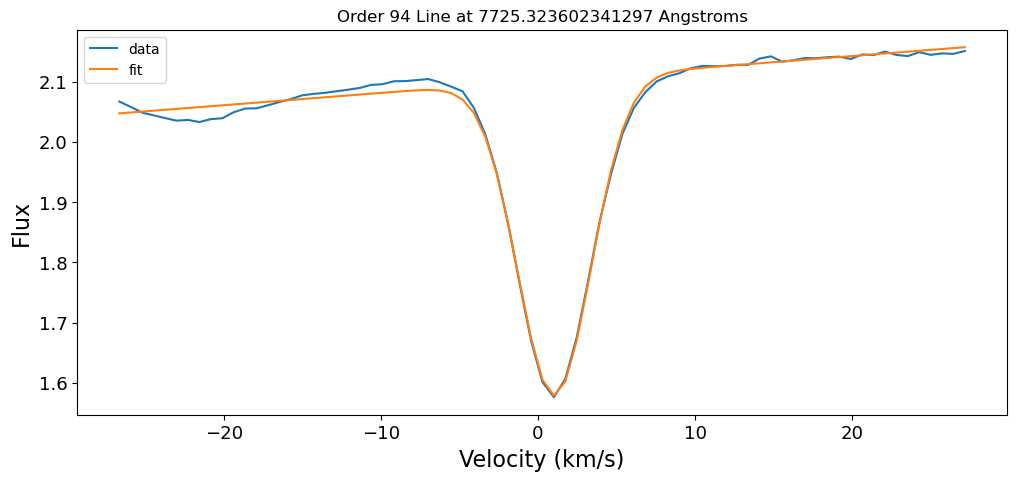

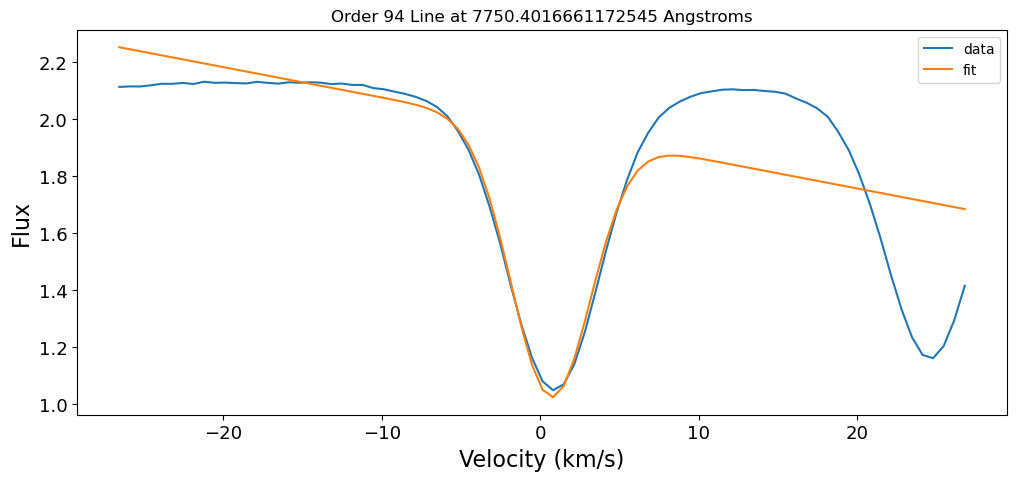

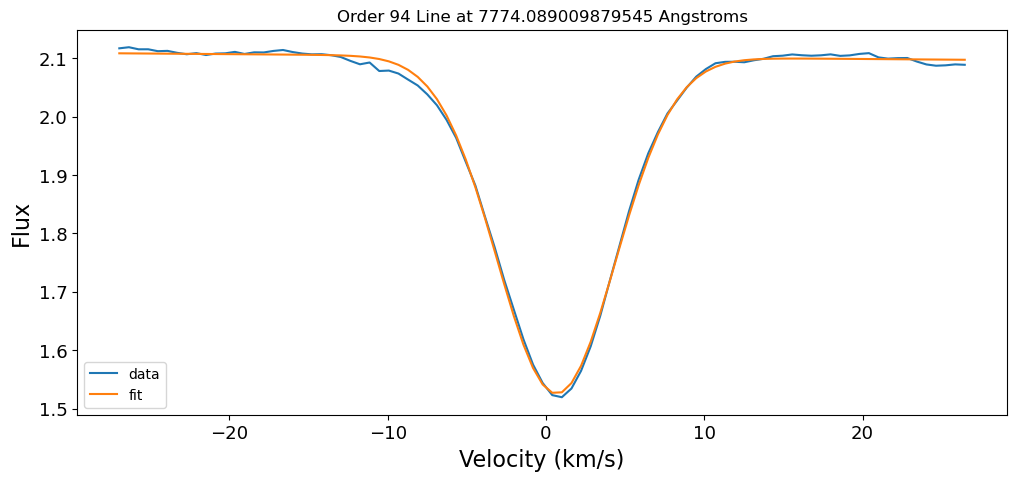

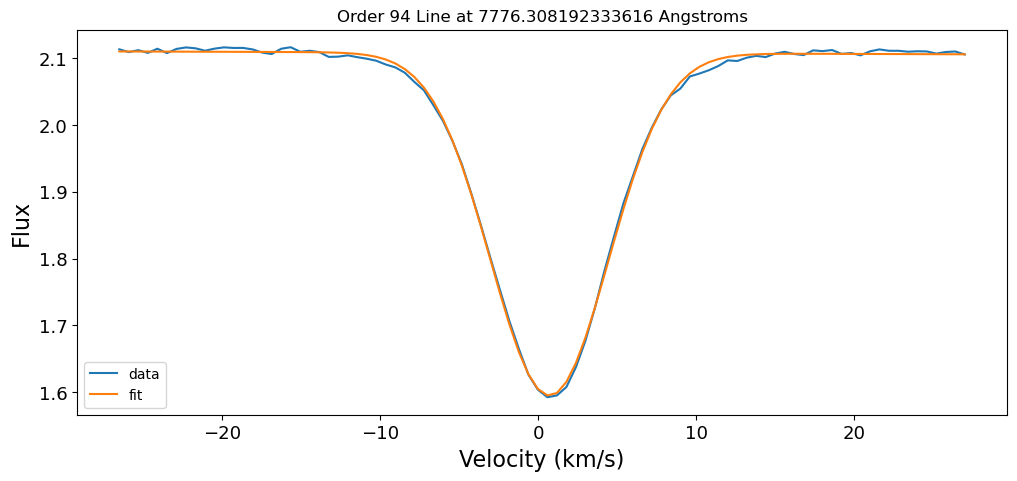

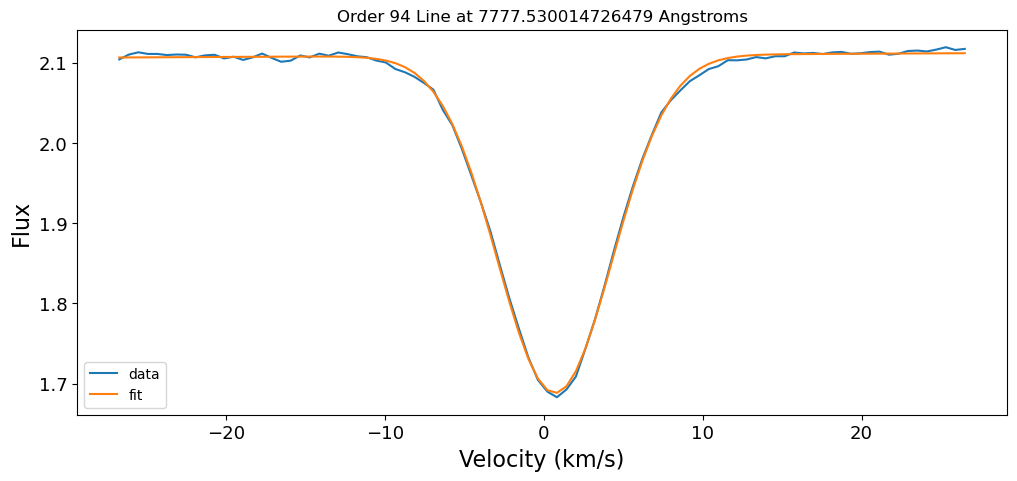

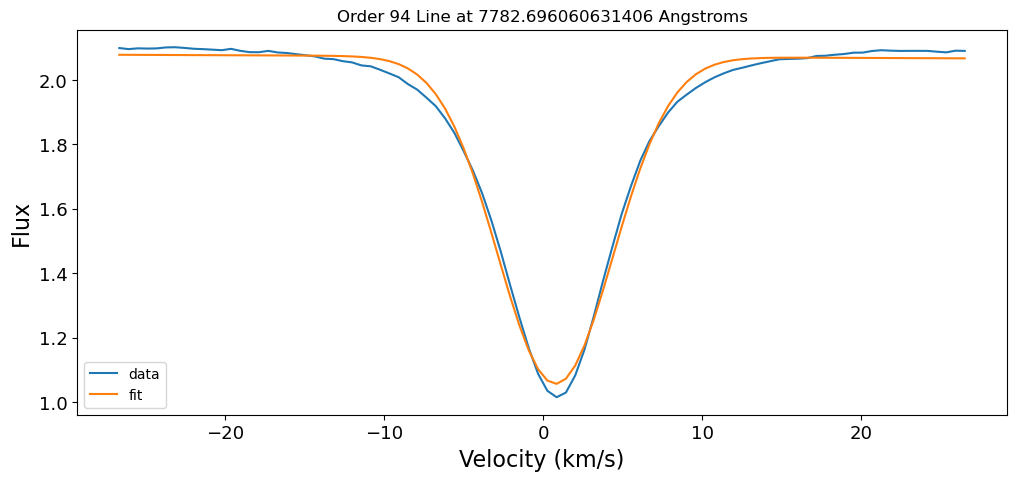

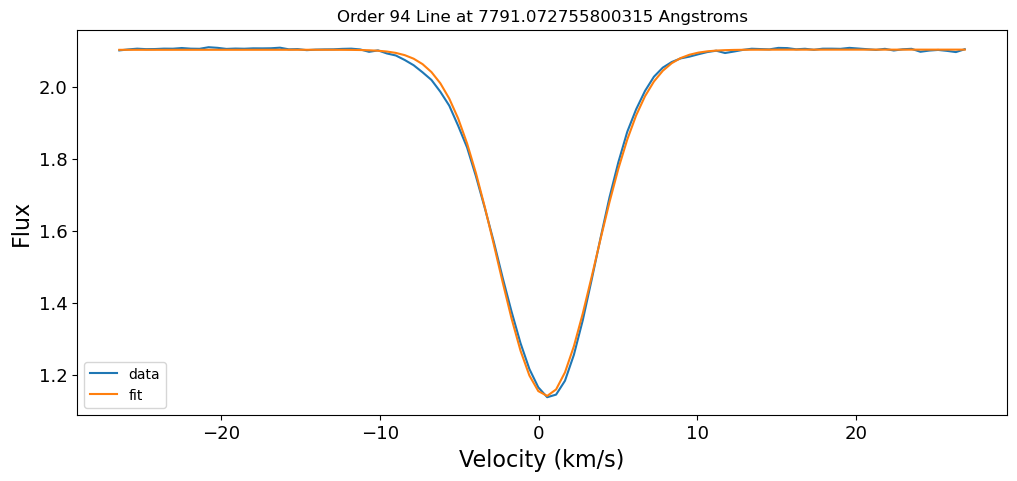

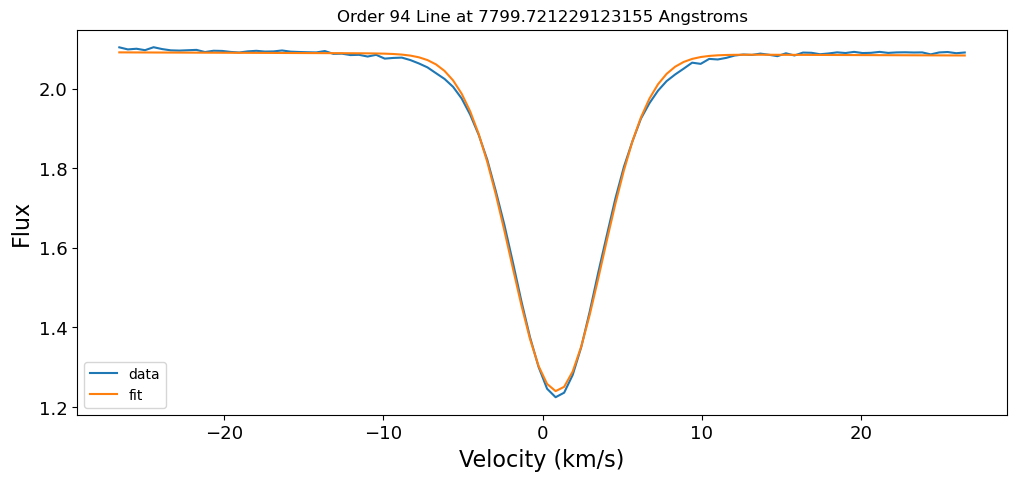

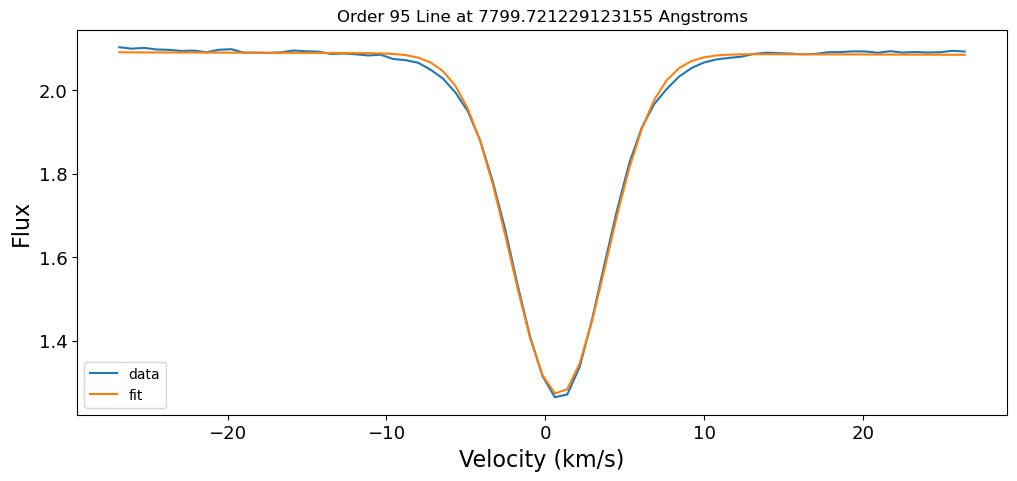

In [24]:
fit_res=fit_lines(w,s,line_list,plot=True,wl_min=7600,wl_max=7800,fit_range=0.7,dist_from_edge=500)

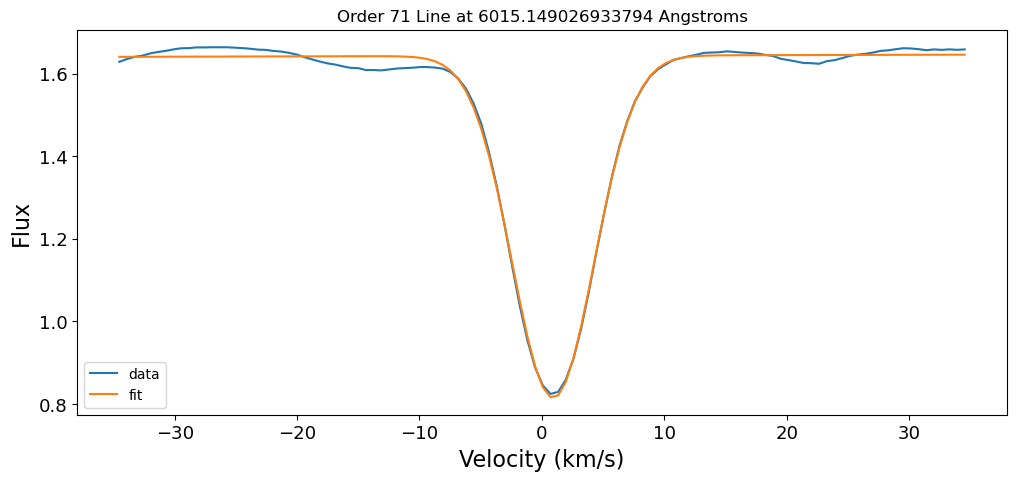

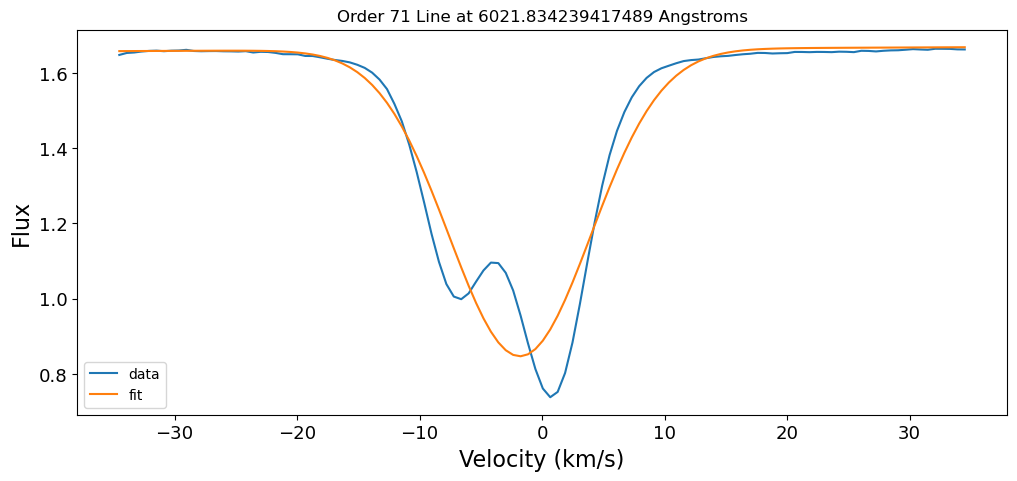

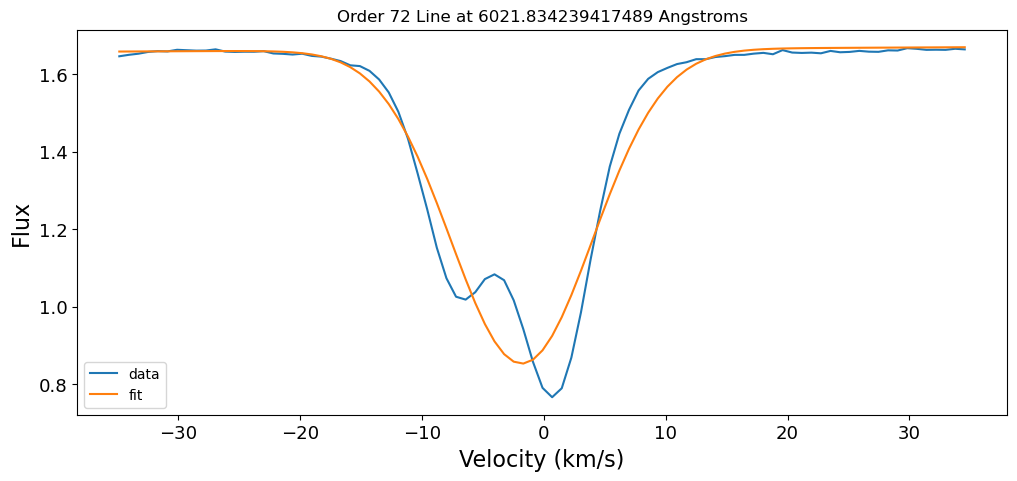

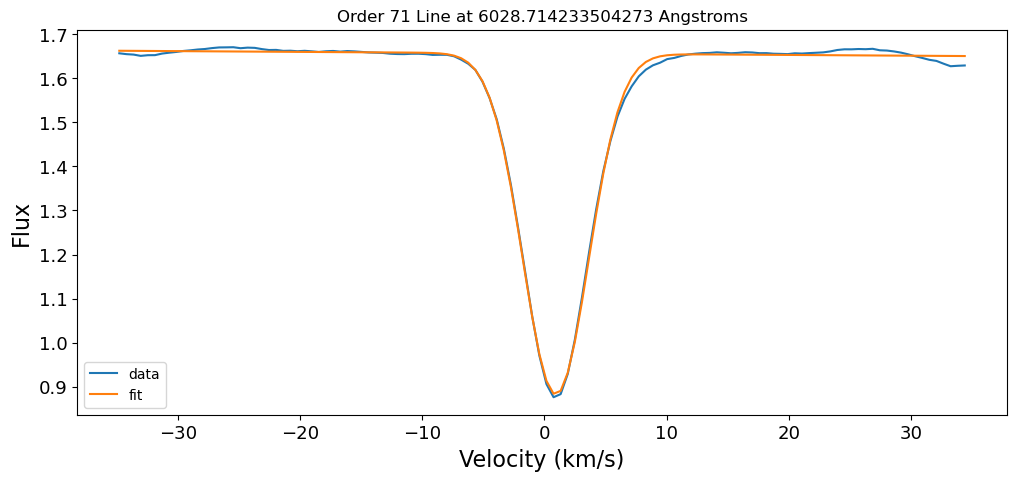

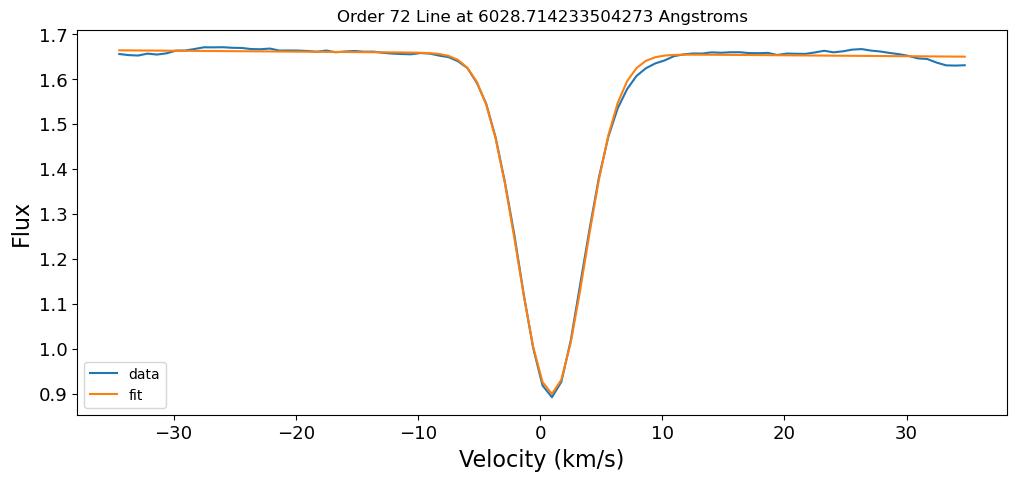

In [ ]:
fit_res=fit_lines(w,s,line_list,plot=True,wl_min=6000,wl_max=6030,fit_range=0.7,dist_from_edge=500)

In [43]:
fit_res

[{'line_wl': 6015.149026933794,
  'order': 71,
  'amp': -6.940273772330941,
  'amp_err': 0.0570652288081479,
  'cen': 0.9223866786670846,
  'cen_err': 0.02749662151029928,
  'wid': 3.34034927732297,
  'wid_err': 0.028889515471153437,
  'bas': 1.6434413581365082,
  'bas_err': 0.0016214938009855582,
  'slope': 7.633237665401615e-05,
  'chi2': 0.02304878740949464,
  'bic': -917.6959764245235,
  'r': 0.9957315637971333,
  'line_center_index': 4381},
 {'line_wl': 6021.834239417489,
  'order': 71,
  'amp': -11.844135633695679,
  'amp_err': 0.39918134937676514,
  'cen': -1.8034276106679252,
  'cen_err': 0.1720114241484587,
  'wid': 5.79045762195029,
  'wid_err': 0.1888933116655215,
  'bas': 1.6631076071002149,
  'bas_err': 0.008604661479113493,
  'slope': 0.0001502539912903629,
  'chi2': 0.520776329677394,
  'bic': -596.9725176105759,
  'r': 0.9386750771067195,
  'line_center_index': 4921},
 {'line_wl': 6021.834239417489,
  'order': 72,
  'amp': -11.797340832500865,
  'amp_err': 0.41452533811

In [40]:
fit_lines(w,s/1.6,line_list,wl_min=6000,wl_max=6030,fit_range=1,dist_from_edge=500)

[{'line_wl': 6015.149026933794,
  'order': 71,
  'amp': -4.36684994561059,
  'amp_err': 0.032781671581873145,
  'cen': 0.9212296912033421,
  'cen_err': 0.026398404555506294,
  'wid': 3.3553856513745193,
  'wid_err': 0.02729626745669309,
  'bas': 1.0288037968290071,
  'bas_err': 0.0007766723405508969,
  'slope': 2.8347579675008174e-05,
  'chi2': 0.012130288749463987,
  'bic': -1482.127157668105,
  'r': 0.9946351859459709,
  'line_center_index': 4381},
 {'line_wl': 6021.834239417489,
  'order': 71,
  'amp': -7.28479347776175,
  'amp_err': 0.18826718564514064,
  'cen': -1.7801943002878373,
  'cen_err': 0.14366009154430034,
  'wid': 5.733293359437225,
  'wid_err': 0.15262757073501199,
  'bas': 1.0356024971919051,
  'bas_err': 0.003409211661217636,
  'slope': 0.00017402208776354727,
  'chi2': 0.21309616580624133,
  'bic': -1072.0432116869115,
  'r': 0.941772301281165,
  'line_center_index': 4921},
 {'line_wl': 6021.834239417489,
  'order': 72,
  'amp': -7.249359865274211,
  'amp_err': 0.197

In [35]:
#time how long this cell takes to run
%time ff=fit_lines(w,s/1.6,line_list,wl_min=3800,wl_max=9030,fit_range=1,dist_from_edge=500)

CPU times: user 25.6 s, sys: 60.2 ms, total: 25.7 s
Wall time: 25.7 s


In [34]:
len(ff)

2896

In [37]:
time_per_spec=25.7
dates=400
specs=2
total_time=time_per_spec*dates*specs/3600  #in hours
print(total_time)

5.711111111111111
